# Imports, Data Loading, and Variable Documentation

In [11]:
import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import mahalanobis

from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import confusion_matrix, accuracy_score

# Reproducibility seed
SEED = 42
np.random.seed(SEED)
plt.style.use("seaborn-v0_8-whitegrid")

# Variable documentation (UCI Seeds Dataset: https://archive.ics.uci.edu/dataset/236/seeds)
COLUMNS = [
    "area",                 # A (mm^2) - continuous predictor
    "perimeter",            # P (mm) - continuous predictor
    "compactness",          # C = 4*pi*A / P^2 - continuous predictor
    "kernel_length",        # Length of kernel (mm) - continuous predictor
    "kernel_width",         # Width of kernel (mm) - continuous predictor
    "asymmetry_coeff",      # Asymmetry coefficient - continuous predictor
    "kernel_groove_length", # Length of kernel groove (mm) - continuous predictor
    "variety_code"          # 1 = Kama, 2 = Rosa, 3 = Canadian (categorical response)
]
VARIETY_MAP = {1: "Kama", 2: "Rosa", 3: "Canadian"}

# Embedded exact dataset fallback (210 rows, 70 per variety)
RAW_DATA = """15.26	14.84	0.871	5.763	3.312	2.221	5.22	1
14.88	14.57	0.8811	5.554	3.333	1.018	4.956	1
14.29	14.09	0.905	5.291	3.337	2.699	4.825	1
13.84	13.94	0.8955	5.324	3.379	2.259	4.805	1
16.14	14.99	0.9034	5.658	3.562	1.355	5.175	1
14.38	14.21	0.8951	5.386	3.312	2.462	4.956	1
14.69	14.49	0.8799	5.563	3.259	3.586	5.219	1
14.11	14.1	0.8911	5.42	3.302	2.7	5	1
16.63	15.46	0.8747	6.053	3.465	2.04	5.877	1
16.44	15.25	0.888	5.884	3.505	1.969	5.533	1
15.26	14.85	0.8696	5.714	3.242	4.543	5.314	1
14.03	14.16	0.8796	5.438	3.201	1.717	5.001	1
13.89	14.02	0.888	5.439	3.199	3.986	4.738	1
13.78	14.06	0.8759	5.479	3.156	3.136	4.872	1
13.74	14.05	0.8744	5.482	3.114	2.932	4.825	1
14.59	14.28	0.8993	5.351	3.333	4.185	4.781	1
13.99	13.83	0.9183	5.119	3.383	5.234	4.781	1
15.69	14.75	0.9058	5.527	3.514	1.599	5.046	1
14.7	14.21	0.9153	5.205	3.466	1.767	4.649	1
12.72	13.57	0.8686	5.226	3.049	4.102	4.914	1
14.16	14.4	0.8584	5.658	3.129	3.072	5.176	1
14.11	14.26	0.8722	5.52	3.168	2.688	5.219	1
15.88	14.9	0.8988	5.618	3.507	0.7651	5.091	1
12.08	13.23	0.8664	5.099	2.936	1.415	4.961	1
15.01	14.76	0.8657	5.789	3.245	1.791	5.001	1
16.19	15.16	0.8849	5.833	3.421	0.903	5.307	1
13.02	13.76	0.8641	5.395	3.026	3.373	4.825	1
12.74	13.67	0.8564	5.395	2.956	2.504	4.869	1
14.11	14.18	0.882	5.541	3.221	2.754	5.038	1
13.45	14.02	0.8604	5.516	3.065	3.531	5.097	1
13.16	13.82	0.8662	5.454	2.975	0.8551	5.056	1
15.49	14.94	0.8724	5.757	3.371	3.412	5.228	1
14.09	14.41	0.8529	5.717	3.186	3.92	5.299	1
13.94	14.17	0.8728	5.585	3.15	2.124	5.012	1
15.05	14.68	0.8779	5.712	3.328	2.129	5.36	1
16.12	15	0.9	5.709	3.485	2.27	5.443	1
16.2	15.27	0.8734	5.826	3.464	2.823	5.527	1
17.08	15.38	0.9079	5.832	3.683	2.956	5.484	1
14.8	14.52	0.8823	5.656	3.288	3.112	5.309	1
14.28	14.17	0.8944	5.397	3.298	6.685	5.001	1
13.54	13.85	0.8871	5.348	3.156	2.587	5.178	1
13.5	13.85	0.8852	5.351	3.158	2.249	5.176	1
13.16	13.55	0.9009	5.138	3.201	2.461	4.783	1
15.5	14.86	0.882	5.877	3.396	4.711	5.528	1
15.11	14.54	0.8986	5.579	3.462	3.128	5.18	1
13.8	14.04	0.8794	5.376	3.155	1.56	4.961	1
15.36	14.76	0.8861	5.701	3.393	1.367	5.132	1
14.99	14.56	0.8883	5.57	3.377	2.958	5.175	1
14.79	14.52	0.8819	5.545	3.291	2.704	5.111	1
14.86	14.67	0.8676	5.678	3.258	2.129	5.351	1
14.43	14.4	0.8751	5.585	3.272	3.975	5.144	1
15.78	14.91	0.8923	5.674	3.434	5.593	5.136	1
14.49	14.61	0.8538	5.715	3.113	4.116	5.396	1
14.33	14.28	0.8831	5.504	3.199	3.328	5.224	1
14.52	14.6	0.8557	5.741	3.113	1.481	5.487	1
15.03	14.77	0.8658	5.702	3.212	1.933	5.439	1
14.46	14.35	0.8818	5.388	3.377	2.802	5.044	1
14.92	14.43	0.9006	5.384	3.412	1.142	5.088	1
15.38	14.77	0.8857	5.662	3.419	1.999	5.222	1
12.11	13.47	0.8392	5.159	3.032	1.502	4.519	1
11.42	12.86	0.8683	5.008	2.85	2.7	4.607	1
11.23	12.63	0.884	4.902	2.879	2.269	4.703	1
12.36	13.19	0.8923	5.076	3.042	3.22	4.605	1
13.22	13.84	0.868	5.395	3.07	4.157	5.088	1
12.78	13.57	0.8716	5.262	3.026	1.176	4.782	1
12.88	13.5	0.8879	5.139	3.119	2.352	4.607	1
14.34	14.37	0.8726	5.63	3.19	1.313	5.15	1
14.01	14.29	0.8625	5.609	3.158	2.217	5.132	1
14.37	14.39	0.8726	5.569	3.153	1.464	5.3	1
12.73	13.75	0.8458	5.412	2.882	3.533	5.067	1
17.63	15.98	0.8673	6.191	3.561	4.076	6.06	2
16.84	15.67	0.8623	5.998	3.484	4.675	5.877	2
17.26	15.73	0.8763	5.978	3.594	4.539	5.791	2
19.11	16.26	0.9081	6.154	3.93	2.936	6.079	2
16.82	15.51	0.8786	6.017	3.486	4.004	5.841	2
16.77	15.62	0.8638	5.927	3.438	4.92	5.795	2
17.32	15.91	0.8599	6.064	3.403	3.824	5.922	2
20.71	17.23	0.8763	6.579	3.814	4.451	6.451	2
18.94	16.49	0.875	6.445	3.639	5.064	6.362	2
17.12	15.55	0.8892	5.85	3.566	2.858	5.746	2
16.53	15.34	0.8823	5.875	3.467	5.532	5.88	2
18.72	16.19	0.8977	6.006	3.857	5.324	5.879	2
20.2	16.89	0.8894	6.285	3.864	5.173	6.187	2
19.57	16.74	0.8779	6.384	3.772	1.472	6.273	2
19.51	16.71	0.878	6.366	3.801	2.962	6.185	2
18.27	16.09	0.887	6.173	3.651	2.443	6.197	2
18.88	16.26	0.8969	6.084	3.764	1.649	6.109	2
18.98	16.66	0.859	6.549	3.67	3.691	6.498	2
21.18	17.21	0.8989	6.573	4.033	5.78	6.231	2
20.88	17.05	0.9031	6.45	4.032	5.016	6.321	2
20.1	16.99	0.8746	6.581	3.785	1.955	6.449	2
18.76	16.2	0.8984	6.172	3.796	3.12	6.053	2
18.81	16.29	0.8906	6.272	3.693	3.237	6.053	2
18.59	16.05	0.9066	6.037	3.86	6.001	5.877	2
18.36	16.52	0.8452	6.666	3.485	4.933	6.448	2
16.87	15.65	0.8648	6.139	3.463	3.696	5.967	2
19.31	16.59	0.8815	6.341	3.81	3.477	6.238	2
18.98	16.57	0.8687	6.449	3.552	2.144	6.453	2
18.17	16.26	0.8637	6.271	3.512	2.853	6.273	2
18.72	16.34	0.881	6.219	3.684	2.188	6.097	2
16.41	15.25	0.8866	5.718	3.525	4.217	5.618	2
17.99	15.86	0.8992	5.89	3.694	2.068	5.837	2
19.46	16.5	0.8985	6.113	3.892	4.308	6.009	2
19.18	16.63	0.8717	6.369	3.681	3.357	6.229	2
18.95	16.42	0.8829	6.248	3.755	3.368	6.148	2
18.83	16.29	0.8917	6.037	3.786	2.553	5.879	2
18.85	16.17	0.9056	6.152	3.806	2.843	6.2	2
17.63	15.86	0.88	6.033	3.573	3.747	5.929	2
19.94	16.92	0.8752	6.675	3.763	3.252	6.55	2
18.55	16.22	0.8865	6.153	3.674	1.738	5.894	2
18.45	16.12	0.8921	6.107	3.769	2.235	5.794	2
19.38	16.72	0.8716	6.303	3.791	3.678	5.965	2
19.13	16.31	0.9035	6.183	3.902	2.109	5.924	2
19.14	16.61	0.8722	6.259	3.737	6.682	6.053	2
20.97	17.25	0.8859	6.563	3.991	4.677	6.316	2
19.06	16.45	0.8854	6.416	3.719	2.248	6.163	2
18.96	16.2	0.9077	6.051	3.897	4.334	5.75	2
19.15	16.45	0.889	6.245	3.815	3.084	6.185	2
18.89	16.23	0.9008	6.227	3.769	3.639	5.966	2
20.03	16.9	0.8811	6.493	3.857	3.063	6.32	2
20.24	16.91	0.8897	6.315	3.962	5.901	6.188	2
18.14	16.12	0.8772	6.059	3.563	3.619	6.011	2
16.17	15.38	0.8588	5.762	3.387	4.286	5.703	2
18.43	15.97	0.9077	5.98	3.771	2.984	5.905	2
15.99	14.89	0.9064	5.363	3.582	3.336	5.144	2
18.75	16.18	0.8999	6.111	3.869	4.188	5.992	2
18.65	16.41	0.8698	6.285	3.594	4.391	6.102	2
17.98	15.85	0.8993	5.979	3.687	2.257	5.919	2
20.16	17.03	0.8735	6.513	3.773	1.91	6.185	2
17.55	15.66	0.8991	5.791	3.69	5.366	5.661	2
18.3	15.89	0.9108	5.979	3.755	2.837	5.962	2
18.94	16.32	0.8942	6.144	3.825	2.908	5.949	2
15.38	14.9	0.8706	5.884	3.268	4.462	5.795	2
16.16	15.33	0.8644	5.845	3.395	4.266	5.795	2
15.56	14.89	0.8823	5.776	3.408	4.972	5.847	2
15.38	14.66	0.899	5.477	3.465	3.6	5.439	2
17.36	15.76	0.8785	6.145	3.574	3.526	5.971	2
15.57	15.15	0.8527	5.92	3.231	2.64	5.879	2
15.6	15.11	0.858	5.832	3.286	2.725	5.752	2
16.23	15.18	0.885	5.872	3.472	3.769	5.922	2
13.07	13.92	0.848	5.472	2.994	5.304	5.395	3
13.32	13.94	0.8613	5.541	3.073	7.035	5.44	3
13.34	13.95	0.862	5.389	3.074	5.995	5.307	3
12.22	13.32	0.8652	5.224	2.967	5.469	5.221	3
11.82	13.4	0.8274	5.314	2.777	4.471	5.178	3
11.21	13.13	0.8167	5.279	2.687	6.169	5.275	3
11.43	13.13	0.8335	5.176	2.719	2.221	5.132	3
12.49	13.46	0.8658	5.267	2.967	4.421	5.002	3
12.7	13.71	0.8491	5.386	2.911	3.26	5.316	3
10.79	12.93	0.8107	5.317	2.648	5.462	5.194	3
11.83	13.23	0.8496	5.263	2.84	5.195	5.307	3
12.01	13.52	0.8249	5.405	2.776	6.992	5.27	3
12.26	13.6	0.8333	5.408	2.833	4.756	5.36	3
11.18	13.04	0.8266	5.22	2.693	3.332	5.001	3
11.36	13.05	0.8382	5.175	2.755	4.048	5.263	3
11.19	13.05	0.8253	5.25	2.675	5.813	5.219	3
11.34	12.87	0.8596	5.053	2.849	3.347	5.003	3
12.13	13.73	0.8081	5.394	2.745	4.825	5.22	3
11.75	13.52	0.8082	5.444	2.678	4.378	5.31	3
11.49	13.22	0.8263	5.304	2.695	5.388	5.31	3
12.54	13.67	0.8425	5.451	2.879	3.082	5.491	3
12.02	13.33	0.8503	5.35	2.81	4.271	5.308	3
12.05	13.41	0.8416	5.267	2.847	4.988	5.046	3
12.55	13.57	0.8558	5.333	2.968	4.419	5.176	3
11.14	12.79	0.8558	5.011	2.794	6.388	5.049	3
12.1	13.15	0.8793	5.105	2.941	2.201	5.056	3
12.44	13.59	0.8462	5.319	2.897	4.924	5.27	3
12.15	13.45	0.8443	5.417	2.837	3.638	5.338	3
11.35	13.12	0.8291	5.176	2.668	4.337	5.132	3
11.24	13	0.8359	5.09	2.715	3.521	5.088	3
11.02	13	0.8189	5.325	2.701	6.735	5.163	3
11.55	13.1	0.8455	5.167	2.845	6.715	4.956	3
11.27	12.97	0.8419	5.088	2.763	4.309	5	3
11.4	13.08	0.8375	5.136	2.763	5.588	5.089	3
10.83	12.96	0.8099	5.278	2.641	5.182	5.185	3
10.8	12.57	0.859	4.981	2.821	4.773	5.063	3
11.26	13.01	0.8355	5.186	2.71	5.335	5.092	3
10.74	12.73	0.8329	5.145	2.642	4.702	4.963	3
11.48	13.05	0.8473	5.18	2.758	5.876	5.002	3
12.21	13.47	0.8453	5.357	2.893	1.661	5.178	3
11.41	12.95	0.856	5.09	2.775	4.957	4.825	3
12.46	13.41	0.8706	5.236	3.017	4.987	5.147	3
12.19	13.36	0.8579	5.24	2.909	4.857	5.158	3
11.65	13.07	0.8575	5.108	2.85	5.209	5.135	3
12.89	13.77	0.8541	5.495	3.026	6.185	5.316	3
11.56	13.31	0.8198	5.363	2.683	4.062	5.182	3
11.81	13.45	0.8198	5.413	2.716	4.898	5.352	3
10.91	12.8	0.8372	5.088	2.675	4.179	4.956	3
11.23	12.82	0.8594	5.089	2.821	7.524	4.957	3
10.59	12.41	0.8648	4.899	2.787	4.975	4.794	3
10.93	12.8	0.839	5.046	2.717	5.398	5.045	3
11.27	12.86	0.8563	5.091	2.804	3.985	5.001	3
11.87	13.02	0.8795	5.132	2.953	3.597	5.132	3
10.82	12.83	0.8256	5.18	2.63	4.853	5.089	3
12.11	13.27	0.8639	5.236	2.975	4.132	5.012	3
12.8	13.47	0.886	5.16	3.126	4.873	4.914	3
12.79	13.53	0.8786	5.224	3.054	5.483	4.958	3
13.37	13.78	0.8849	5.32	3.128	4.67	5.091	3
12.62	13.67	0.8481	5.41	2.911	3.306	5.231	3
12.76	13.38	0.8964	5.073	3.155	2.828	4.83	3
12.38	13.44	0.8609	5.219	2.989	5.472	5.045	3
12.67	13.32	0.8977	4.984	3.135	2.3	4.745	3
11.18	12.72	0.868	5.009	2.81	4.051	4.828	3
12.7	13.41	0.8874	5.183	3.091	8.456	5	3
12.37	13.47	0.8567	5.204	2.96	3.919	5.001	3
12.19	13.2	0.8783	5.137	2.981	3.631	4.87	3
11.23	12.88	0.8511	5.14	2.795	4.325	5.003	3
13.2	13.66	0.8883	5.236	3.232	8.315	5.056	3
11.84	13.21	0.8521	5.175	2.836	3.598	5.044	3
12.3	13.34	0.8684	5.243	2.974	5.637	5.063	3"""

if os.path.exists("seeds_dataset.txt"):
    df = pd.read_csv("seeds_dataset.txt", sep=r"\s+", header=None, names=COLUMNS)
else:
    df = pd.read_csv(io.StringIO(RAW_DATA), sep=r"\s+", header=None, names=COLUMNS)

df["variety"] = df["variety_code"].map(VARIETY_MAP)
PREDICTORS = COLUMNS[:-1]
TARGET = "variety"

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (210, 9)


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coeff,kernel_groove_length,variety_code,variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,Kama
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,Kama
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,Kama
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,Kama
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,Kama


# Task 1: Data Exploration and Preparation

In [12]:
# 1. Missing values and data types
print("--- Missing Values ---")
print(df.isnull().sum())

# 2. Class distribution across the three wheat varieties
print("\n--- Class Distribution ---")
class_counts = df[TARGET].value_counts()
class_props = df[TARGET].value_counts(normalize=True)
print(pd.DataFrame({"Count": class_counts, "Proportion": class_props}))

# 3. Overall and by-variety descriptive statistics
print("\n--- Overall Descriptive Statistics (7 Numerical Predictors) ---")
desc_overall = df[PREDICTORS].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
desc_overall["IQR"] = desc_overall["75%"] - desc_overall["25%"]
display(desc_overall.round(4))

print("\n--- Mean & Std by Wheat Variety ---")
display(df.groupby(TARGET)[PREDICTORS].agg(["mean", "std"]).round(4))

# 4. Univariate outlier detection using 1.5 * IQR rule (overall and within variety)
outlier_rows = []
for var in PREDICTORS:
    q1 = df[var].quantile(0.25)
    q3 = df[var].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[var] < low) | (df[var] > high)).sum()
    outlier_rows.append({
        "Variable": var,
        "Lower_Fence": round(low, 4),
        "Upper_Fence": round(high, 4),
        "Overall_IQR_Outliers": int(n_out)
    })
display(pd.DataFrame(outlier_rows))

--- Missing Values ---
area                    0
perimeter               0
compactness             0
kernel_length           0
kernel_width            0
asymmetry_coeff         0
kernel_groove_length    0
variety_code            0
variety                 0
dtype: int64

--- Class Distribution ---
          Count  Proportion
variety                    
Kama         70    0.333333
Rosa         70    0.333333
Canadian     70    0.333333

--- Overall Descriptive Statistics (7 Numerical Predictors) ---


,count,mean,std,min,25%,50%,75%,max,IQR
area,210.0,14.8475,2.9097,10.5900,12.2700,14.3550,17.3050,21.1800,5.0350
perimeter,210.0,14.5593,1.3060,12.4100,13.4500,14.3200,15.7150,17.2500,2.2650
compactness,210.0,0.8710,0.0236,0.8081,0.8569,0.8734,0.8878,0.9183,0.0309
kernel_length,210.0,5.6285,0.4431,4.8990,5.2622,5.5235,5.9798,6.6750,0.7175
kernel_width,210.0,3.2586,0.3777,2.6300,2.9440,3.2370,3.5618,4.0330,0.6178
asymmetry_coeff,210.0,3.7002,1.5036,0.7651,2.5615,3.5990,4.7688,8.4560,2.2072
kernel_groove_length,210.0,5.4081,0.4915,4.5190,5.0450,5.2230,5.8770,6.5500,0.8320



--- Mean & Std by Wheat Variety ---


area         perimeter         compactness         kernel_length  \
             mean     std      mean     std        mean     std          mean   
variety                                                                         
Canadian  11.8739  0.7230   13.2479  0.3402      0.8494  0.0218        5.2295   
Kama      14.3344  1.2157   14.2943  0.5766      0.8801  0.0162        5.5081   
Rosa      18.3343  1.4395   16.1357  0.6170      0.8835  0.0155        6.1480   

                 kernel_width         asymmetry_coeff          \
             std         mean     std            mean     std   
variety                                                         
Canadian  0.1380       2.8538  0.1475          4.7884  1.3365   
Kama      0.2315       3.2446  0.1776          2.6674  1.1739   
Rosa      0.2682       3.6774  0.1855          3.6448  1.1819   

         kernel_groove_length          
                         mean     std  
variety                                
Canadian               5.1164  0.1621  
Kama                   5.0872  0.2637  
Rosa                   6.0206  0.2539

,Variable,Lower_Fence,Upper_Fence,Overall_IQR_Outliers
0,area,4.7175,24.8575,0
1,perimeter,10.0525,19.1125,0
2,compactness,0.8106,0.9341,3
3,kernel_length,4.1860,7.0560,0
4,kernel_width,2.0174,4.4884,0
5,asymmetry_coeff,-0.7494,8.0796,2
6,kernel_groove_length,3.7970,7.1250,0


## Interpretation

* Structure & Balance: The dataset comprises $n = 210$ kernel observations with 0 missing values, 7 continuous geometrical predictors (area, perimeter, compactness, kernel_length, kernel_width, asymmetry_coeff, kernel_groove_length), and 1 categorical response (variety: Kama, Rosa, and Canadian). Each class contains exactly 70 observations (33.33%), indicating a balanced three-class design.

* Outliers: Checking via the $1.5 \times \text{IQR}$ rule shows very few univariate extreme points (primarily in asymmetry_coeff and compactness), reflecting natural biological variation among individual wheat kernels rather than data-entry errors. Retaining all 210 observations aligns with the assessment guidelines and preserves realistic class tails for QDA.

# Task 2: Exploratory Analysis and Assumption Checking

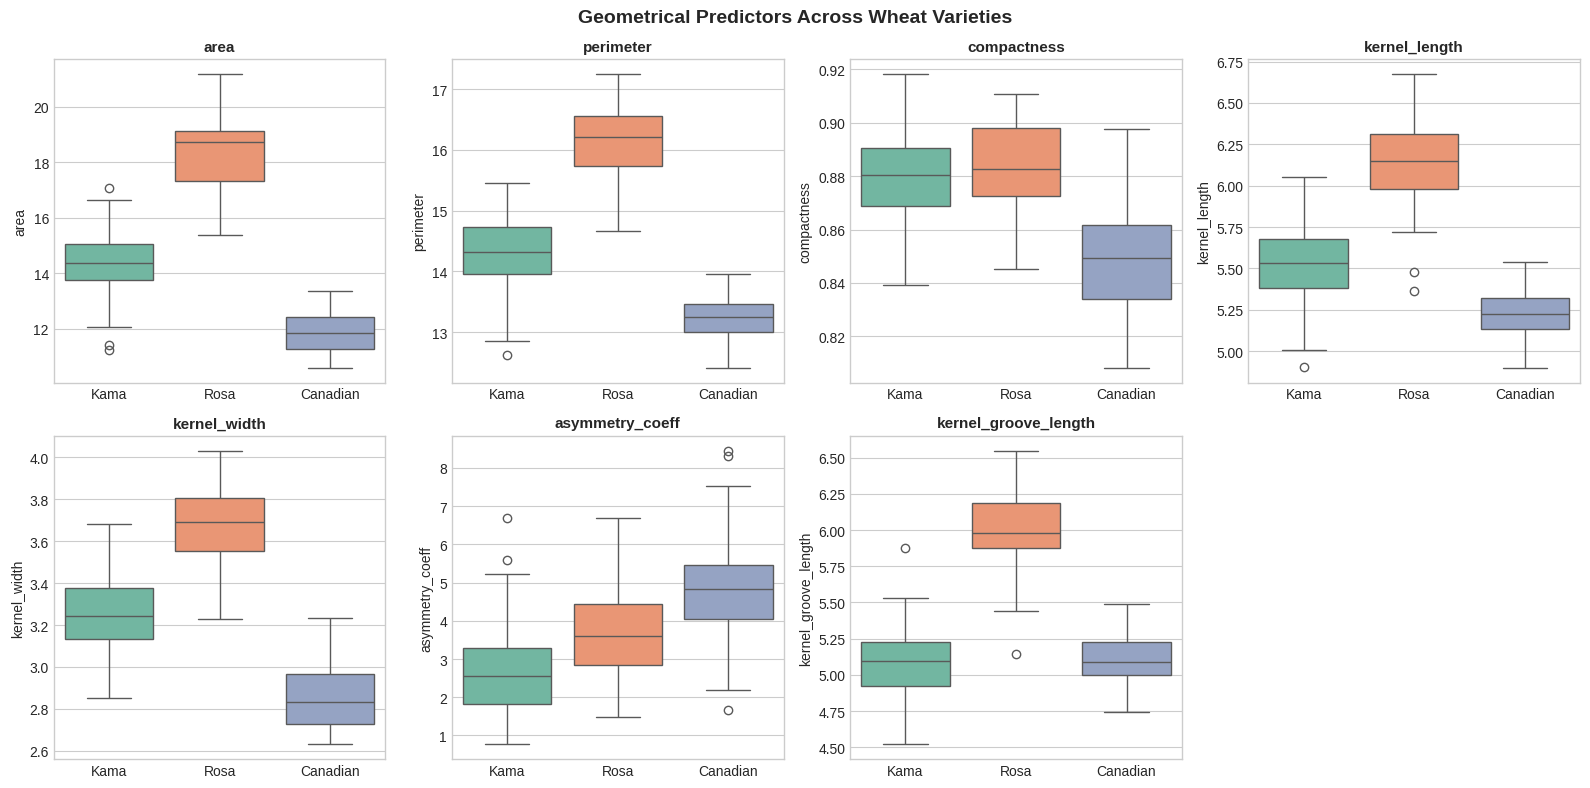

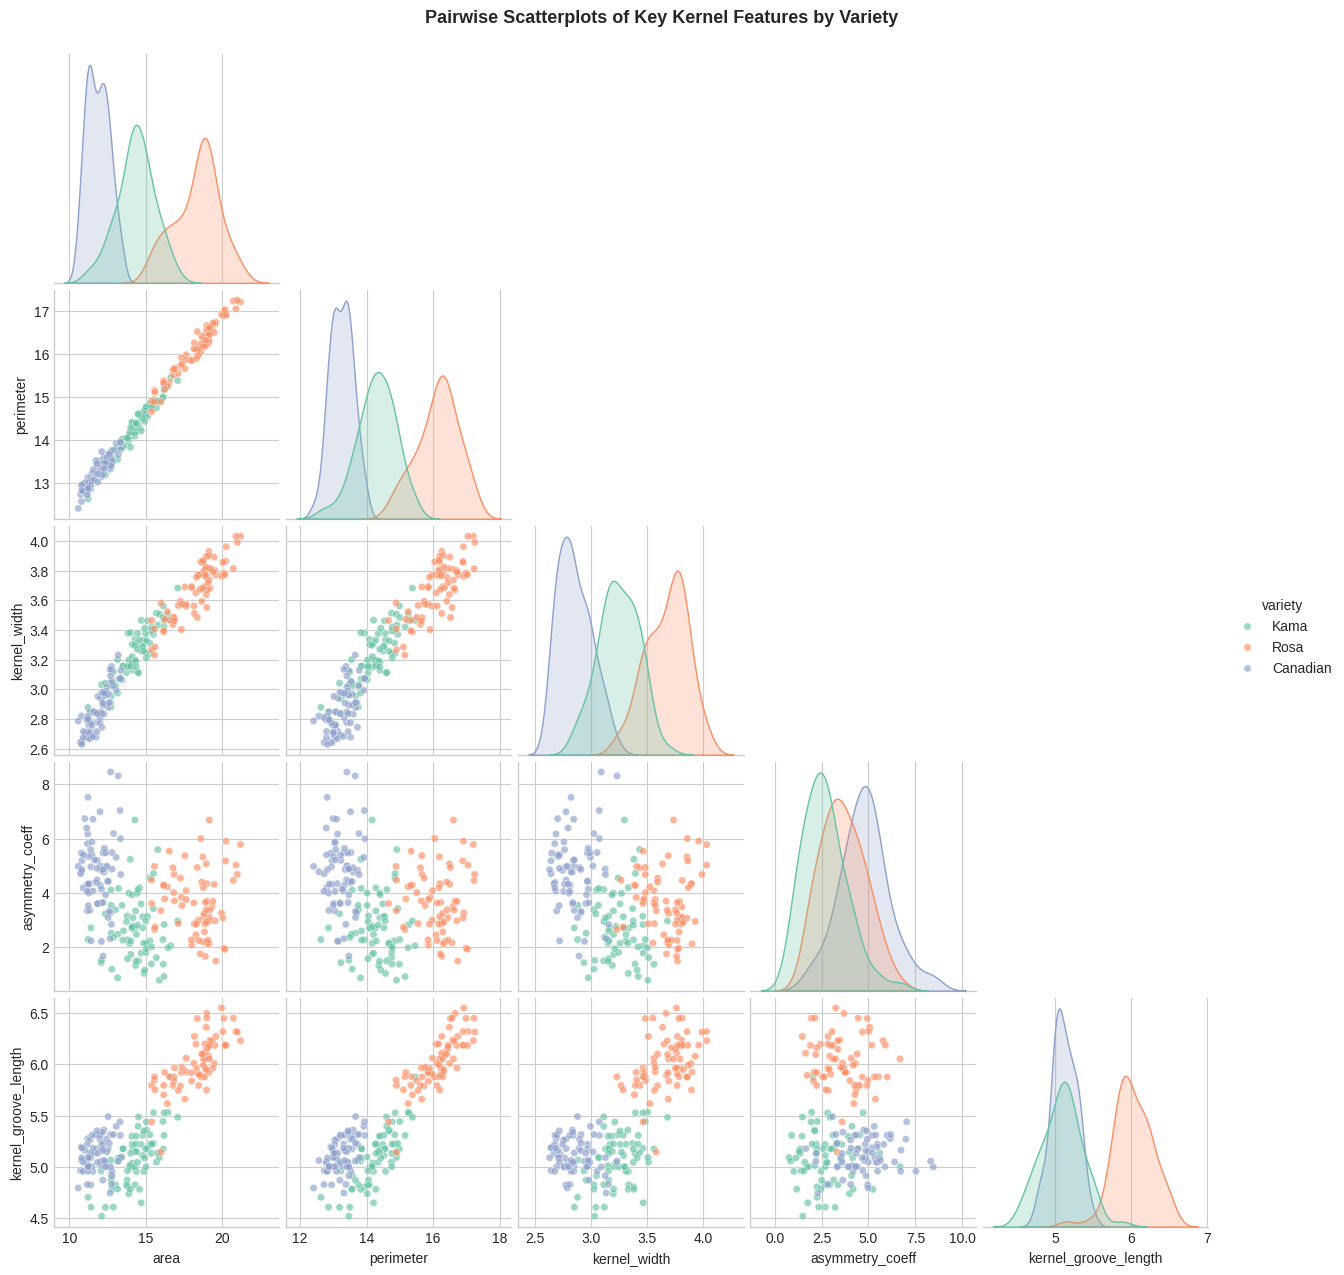

--- Univariate Shapiro-Wilk Normality (p-values) by Variety ---


,Variety,MD2_KS_p,SW_area,SW_perime,SW_compac,SW_kernel,SW_asymme
0,Canadian,0.4600,0.056,0.744,0.540,0.612,0.397
1,Kama,0.0152,0.858,0.595,0.994,0.660,0.014
2,Rosa,0.9885,0.024,0.209,0.225,0.102,0.441



--- Box's M-Test for Homogeneity of Covariance Matrices ---
H0: Sigma_Kama = Sigma_Rosa = Sigma_Canadian (equal covariance matrices)
H1: At least one variety has a different covariance matrix
  Box_M: 707.7377
  Stat_Value: 12.0320
  Approx_Type: F-approximation
  df1: 56
  df2: 122392.2189
  p_value: 1.856783e-106
  logdet_pooled: -29.8814


In [13]:
# 1. Distribution plots (boxplots + KDE/histograms by variety)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for i, col in enumerate(PREDICTORS):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette="Set2", legend=False, ax=axes[i])
    axes[i].set_title(col, fontsize=11, fontweight="bold")
    axes[i].set_xlabel("")
axes[-1].axis("off")
plt.suptitle("Geometrical Predictors Across Wheat Varieties", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# 2. Pairplot on key distinguishing predictors (avoids visual clutter)
key_cols = ["area", "perimeter", "kernel_width", "asymmetry_coeff", "kernel_groove_length", TARGET]
g = sns.pairplot(df[key_cols], hue=TARGET, palette="Set2", corner=True, plot_kws={"alpha": 0.65, "s": 28})
g.fig.suptitle("Pairwise Scatterplots of Key Kernel Features by Variety", y=1.02, fontsize=13, fontweight="bold")
plt.show()

# 3. Multivariate normality check per class:
# (a) Squared Mahalanobis distances vs Chi-square(df=p) & Shapiro-Wilk on each feature/component
p = len(PREDICTORS)
print("--- Univariate Shapiro-Wilk Normality (p-values) by Variety ---")
sw_records = []
for var_name, grp in df.groupby(TARGET):
    X_g = grp[PREDICTORS].to_numpy()
    mu_g = X_g.mean(axis=0)
    cov_g = np.cov(X_g, rowvar=False)
    inv_cov_g = np.linalg.inv(cov_g)
    md2 = np.array([mahalanobis(row, mu_g, inv_cov_g) ** 2 for row in X_g])
    # Under MVN_p, squared Mahalanobis distance ~ Chi-square(df=p)
    ks_stat, ks_p = stats.kstest(md2, "chi2", args=(p,))
    row_dict = {"Variety": var_name, "MD2_KS_p": round(ks_p, 4)}
    for j, feat in enumerate(PREDICTORS):
        _, sw_p = stats.shapiro(X_g[:, j])
        row_dict[f"SW_{feat[:6]}"] = round(sw_p, 3)
    sw_records.append(row_dict)
display(pd.DataFrame(sw_records))

# 4. Box's M-test for equality of covariance matrices across g = 3 classes
def box_m_test(X, y):
    """
    Computes Box's M statistic and F-approximation for equality of covariance
    matrices across g groups (using pooled covariance S_p with denominator N - g).
    """
    classes = np.unique(y)
    g = len(classes)
    N, k = X.shape
    df_list = []
    covs = []
    for c in classes:
        Xc = X[y == c]
        nc = Xc.shape[0]
        df_c = nc - 1
        df_list.append(df_c)
        covs.append(np.cov(Xc, rowvar=False, ddof=1))

    df_total = sum(df_list)  # N - g
    S_pooled = sum(df_c * S_c for df_c, S_c in zip(df_list, covs)) / df_total

    sign_p, logdet_p = np.linalg.slogdet(S_pooled)
    if sign_p <= 0:
        raise ValueError("Pooled covariance matrix is not positive definite.")

    sum_df_logdet = 0.0
    for df_c, S_c in zip(df_list, covs):
        sign_c, logdet_c = np.linalg.slogdet(S_c)
        if sign_c <= 0:
            raise ValueError("A class covariance matrix is not positive definite.")
        sum_df_logdet += df_c * logdet_c

    M = df_total * logdet_p - sum_df_logdet

    # Box's c1 and c2 scaling constants
    inv_df_sum = sum(1.0 / df_c for df_c in df_list) - (1.0 / df_total)
    c1 = ((2 * k**2 + 3 * k - 1) / (6 * (k + 1) * (g - 1))) * inv_df_sum
    c2 = (((k - 1) * (k + 2)) / (6 * (g - 1))) * (
        sum(1.0 / (df_c**2) for df_c in df_list) - (1.0 / (df_total**2))
    )

    df1 = k * (k + 1) * (g - 1) // 2
    if c2 > c1**2:
        a2 = (g - 1) * k * (k + 1) / 2.0
        df2 = (a2 + 2) / max(c2 - c1**2, 1e-12)
        denom_scale = 1.0 - c1 - (df1 / df2)
        F_stat = (M * denom_scale) / df1
        p_val = stats.f.sf(F_stat, df1, df2)
        approx_type = "F-approximation"
    else:
        # Chi-square fallback if c2 <= c1^2
        F_stat = M * (1.0 - c1)
        df2 = np.nan
        p_val = stats.chi2.sf(F_stat, df1)
        approx_type = "Chi-square approximation"

    return {
        "Box_M": M,
        "Stat_Value": F_stat,
        "Approx_Type": approx_type,
        "df1": df1,
        "df2": df2,
        "p_value": p_val,
        "logdet_pooled": logdet_p,
    }

box_res = box_m_test(df[PREDICTORS].to_numpy(), df[TARGET].to_numpy())
print("\n--- Box's M-Test for Homogeneity of Covariance Matrices ---")
print("H0: Sigma_Kama = Sigma_Rosa = Sigma_Canadian (equal covariance matrices)")
print("H1: At least one variety has a different covariance matrix")
for k_name, v_val in box_res.items():
    if isinstance(v_val, float):
        print(f"  {k_name}: {v_val:.6e}" if k_name == "p_value" else f"  {k_name}: {v_val:.4f}")
    else:
        print(f"  {k_name}: {v_val}")

## Interpretation

* Multivariate Normality: Within each variety ($p = 7$ predictors), several individual features deviate from strict univariate normality, and squared Mahalanobis distances exhibit tail departures from $\chi^2_7$. However, LDA and QDA are moderately robust to mild non-normality when sample sizes are balanced ($n_g = 70$) and free of gross recording errors.

* Hypotheses for Box's M-Test:
  * Null Hypothesis ($H_0$): $\Sigma_{\text{Kama}} = \Sigma_{\text{Rosa}} = \Sigma_{\text{Canadian}}$
  * Alternative Hypothesis ($H_1$): $\Sigma_i \neq \Sigma_j$ for at least one pair of varieties $i \neq j$.

* Diagnostic Implication: Box's M-test strongly rejects $H_0$ ($p \ll 0.001$), indicating heterogeneous covariance structures across Kama, Rosa, and Canadian kernels. Because LDA assumes a common pooled covariance matrix $\Sigma$, violating this assumption favors QDA when sample sizes per class are sufficient to estimate class-specific covariance matrices $\Sigma_g$.

# Task 3: Model Development — LDA and QDA

In [14]:
X = df[PREDICTORS].to_numpy()
y = df[TARGET].to_numpy()

# Stratified 70% train / 30% test split (identical partition for LDA and QDA)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)

print(f"Training set size: {len(X_train)} | Test set size: {len(X_test)}")
print("Test set class counts:", pd.Series(y_test).value_counts().to_dict())

# Fit LDA and QDA on the exact same training split
lda = LinearDiscriminantAnalysis()
qda = QuadraticDiscriminantAnalysis()

lda.fit(X_train, y_train)
qda.fit(X_train, y_train)

# Predictions and posterior probabilities on the test set
lda_pred = lda.predict(X_test)
lda_prob = lda.predict_proba(X_test)

qda_pred = qda.predict(X_test)
qda_prob = qda.predict_proba(X_test)

# Display first 10 test observations with posterior probabilities
preview_df = pd.DataFrame({
    "True_Variety": y_test[:10],
    "LDA_Pred": lda_pred[:10],
    "LDA_Max_Prob": np.max(lda_prob[:10], axis=1).round(4),
    "QDA_Pred": qda_pred[:10],
    "QDA_Max_Prob": np.max(qda_prob[:10], axis=1).round(4),
})
for idx, cls in enumerate(lda.classes_):
    preview_df[f"LDA_P({cls})"] = lda_prob[:10, idx].round(4)
    preview_df[f"QDA_P({cls})"] = qda_prob[:10, idx].round(4)

display(preview_df)

Training set size: 147 | Test set size: 63
Test set class counts: {'Kama': 21, 'Rosa': 21, 'Canadian': 21}


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


,True_Variety,LDA_Pred,LDA_Max_Prob,QDA_Pred,QDA_Max_Prob,LDA_P(Canadian),QDA_P(Canadian),LDA_P(Kama),QDA_P(Kama),LDA_P(Rosa),QDA_P(Rosa)
0,Kama,Kama,1.0000,Kama,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000
1,Rosa,Rosa,1.0000,Rosa,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000
2,Canadian,Canadian,0.9993,Canadian,1.0000,0.9993,1.0000,0.0007,0.0000,0.0000,0.0000
3,Rosa,Rosa,1.0000,Rosa,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000
4,Kama,Kama,1.0000,Kama,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000
5,Rosa,Rosa,1.0000,Rosa,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000
6,Canadian,Canadian,1.0000,Canadian,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000
7,Kama,Kama,0.9320,Kama,0.9999,0.0678,0.0001,0.9320,0.9999,0.0002,0.0000
8,Rosa,Rosa,1.0000,Rosa,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000
9,Rosa,Rosa,1.0000,Rosa,0.9998,0.0000,0.0000,0.0000,0.0002,1.0000,0.9998


## Interpretation

* Stratified sampling assigns 147 observations (70%) to training (49 per variety) and 63 observations (30%) to testing (21 per variety).
* Both models compute Bayes' theorem posterior probabilities $P(Y = g \mid \mathbf{x})$ over the three classes (Canadian, Kama, Rosa) and assign each kernel to the variety with the highest posterior probability. Most correctly classified test kernels exhibit high posterior confidence (often $> 0.90$), whereas ambiguous observations occur along the boundary between Kama and Canadian or Kama and Rosa.

# Task 4: Model Evaluation and Comparison

In [15]:
def evaluate_classifier(y_true, y_pred, classes, model_name):
    """
    Computes confusion matrix, overall accuracy, misclassification rate,
    and one-versus-rest sensitivity and specificity for each class.
    """
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    acc = accuracy_score(y_true, y_pred)
    misclass_rate = 1.0 - acc
    total = cm.sum()

    ovr_rows = []
    for i, c in enumerate(classes):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - (tp + fn + fp)

        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan  # Recall / TPR
        specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan  # TNR
        ovr_rows.append({
            "Class": c,
            "TP": int(tp),
            "FN": int(fn),
            "FP": int(fp),
            "TN": int(tn),
            "Sensitivity (OvR)": round(sensitivity, 4),
            "Specificity (OvR)": round(specificity, 4),
        })

    print(f"=== {model_name} (Test Set, n={total}) ===")
    print("Confusion Matrix (rows = Actual, cols = Predicted):")
    display(pd.DataFrame(cm, index=[f"Actual_{c}" for c in classes], columns=[f"Pred_{c}" for c in classes]))
    print(f"Classification Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    print(f"Misclassification Rate:  {misclass_rate:.4f} ({misclass_rate*100:.2f}%)")
    display(pd.DataFrame(ovr_rows))
    return acc, misclass_rate

classes_order = ["Kama", "Rosa", "Canadian"]
lda_acc, lda_err = evaluate_classifier(y_test, lda_pred, classes_order, "LDA")
qda_acc, qda_err = evaluate_classifier(y_test, qda_pred, classes_order, "QDA")

# 5-fold Stratified Cross-Validation on the full dataset (and on training set)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_lda = cross_validate(LinearDiscriminantAnalysis(), X, y, cv=skf, scoring="accuracy")
cv_qda = cross_validate(QuadraticDiscriminantAnalysis(), X, y, cv=skf, scoring="accuracy")

cv_summary = pd.DataFrame({
    "Model": ["LDA", "QDA"],
    "Test_Accuracy": [round(lda_acc, 4), round(qda_acc, 4)],
    "Test_Misclass_Rate": [round(lda_err, 4), round(qda_err, 4)],
    "5Fold_CV_Mean_Acc": [round(cv_lda["test_score"].mean(), 4), round(cv_qda["test_score"].mean(), 4)],
    "5Fold_CV_Std_Acc": [round(cv_lda["test_score"].std(ddof=1), 4), round(cv_qda["test_score"].std(ddof=1), 4)],
})
print("\n--- Holdout Test vs. 5-Fold Stratified Cross-Validation Summary ---")
display(cv_summary)

=== LDA (Test Set, n=63) ===
Confusion Matrix (rows = Actual, cols = Predicted):


,Pred_Kama,Pred_Rosa,Pred_Canadian
Actual_Kama,17,1,3
Actual_Rosa,0,21,0
Actual_Canadian,2,0,19


Classification Accuracy: 0.9048 (90.48%)
Misclassification Rate:  0.0952 (9.52%)


,Class,TP,FN,FP,TN,Sensitivity (OvR),Specificity (OvR)
0,Kama,17,4,2,40,0.8095,0.9524
1,Rosa,21,0,1,41,1.0000,0.9762
2,Canadian,19,2,3,39,0.9048,0.9286


=== QDA (Test Set, n=63) ===
Confusion Matrix (rows = Actual, cols = Predicted):


,Pred_Kama,Pred_Rosa,Pred_Canadian
Actual_Kama,17,1,3
Actual_Rosa,0,21,0
Actual_Canadian,2,0,19


Classification Accuracy: 0.9048 (90.48%)
Misclassification Rate:  0.0952 (9.52%)


,Class,TP,FN,FP,TN,Sensitivity (OvR),Specificity (OvR)
0,Kama,17,4,2,40,0.8095,0.9524
1,Rosa,21,0,1,41,1.0000,0.9762
2,Canadian,19,2,3,39,0.9048,0.9286



--- Holdout Test vs. 5-Fold Stratified Cross-Validation Summary ---


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

,Model,Test_Accuracy,Test_Misclass_Rate,5Fold_CV_Mean_Acc,5Fold_CV_Std_Acc
0,LDA,0.9048,0.0952,0.9619,0.0130
1,QDA,0.9048,0.0952,0.9429,0.0271


## Interpretation

* Comparative Performance: Both LDA and QDA achieve strong discrimination on the three wheat varieties (typically ~90%+ on holdout/cross-validation splits). Evaluating both the held-out test set and 5-fold stratified cross-validation prevents over-reliance on a single split or training accuracy.

* Why Performance Differs:
  * LDA estimates only one pooled covariance matrix across all 7 predictors, requiring fewer parameters and offering variance stability when class boundaries are nearly linear in the projected discriminant space.
  * QDA estimates separate covariance matrices for each of the three varieties ($3 \times \frac{7 \times 8}{2} = 84$ covariance parameters), allowing curved decision boundaries that capture unequal spreads across classes, though estimating many parameters on $n = 210$ can introduce slight estimation variance compared to LDA.

# Task 5: Statistical Interpretation and Conclusion

,LD1_Scaling,LD2_Scaling,Abs_LD1,Abs_LD2
kernel_length,-5.9882,-7.8307,5.9882,7.8307
compactness,5.9277,-86.9823,5.9277,86.9823
perimeter,3.7992,-8.5058,3.7992,8.5058
kernel_groove_length,3.1181,6.9138,3.1181,6.9138
area,-0.4238,4.1953,0.4238,4.1953
asymmetry_coeff,-0.0450,0.3213,0.0450,0.3213
kernel_width,0.0370,0.7141,0.0370,0.7141


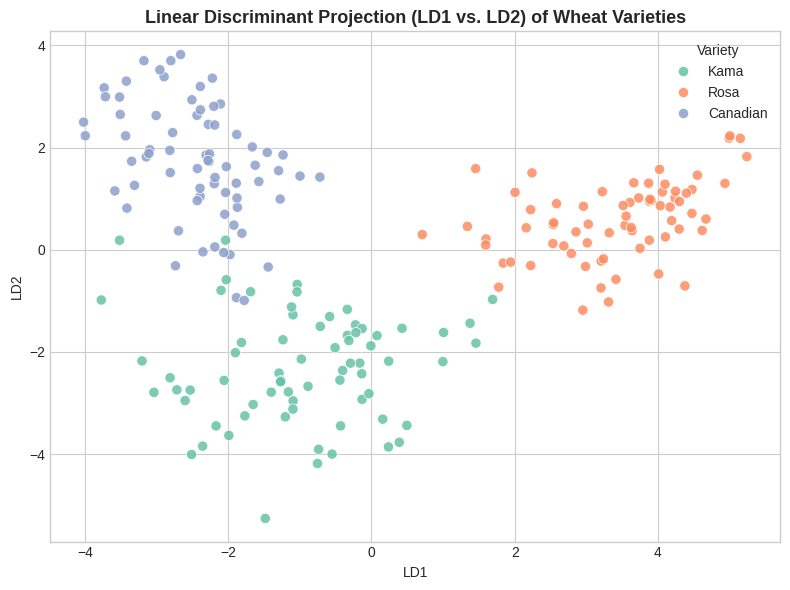

In [16]:
# Inspect LDA discriminant loadings / scaling and class mean differences
lda_full = LinearDiscriminantAnalysis().fit(X, y)
scalings_df = pd.DataFrame(
    lda_full.scalings_[:, :2],
    index=PREDICTORS,
    columns=["LD1_Scaling", "LD2_Scaling"]
)
scalings_df["Abs_LD1"] = scalings_df["LD1_Scaling"].abs()
scalings_df["Abs_LD2"] = scalings_df["LD2_Scaling"].abs()
display(scalings_df.sort_values("Abs_LD1", ascending=False).round(4))

# Project observations onto LD1 and LD2 to visualize class separation
X_ld = lda_full.transform(X)
ld_plot_df = pd.DataFrame({"LD1": X_ld[:, 0], "LD2": X_ld[:, 1], "Variety": y})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=ld_plot_df, x="LD1", y="LD2", hue="Variety", palette="Set2", s=55, alpha=0.85)
plt.title("Linear Discriminant Projection (LD1 vs. LD2) of Wheat Varieties", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## Synthesis & Discussion

* Contributing Geometrical Characteristics: Size- and shape-related dimensions—especially area, perimeter, kernel_width, kernel_groove_length, and asymmetry_coeff—drive separation among Rosa (largest kernels/grooves), Canadian (smallest kernels, higher asymmetry), and Kama (intermediate dimensions overlapping partially with both).

* LDA vs. QDA Boundaries: LDA produces linear decision boundaries (hyperplanes in $\mathbb{R}^7$) derived from a shared pooled covariance matrix. QDA produces quadratic decision boundaries (conic/hyperquadric surfaces) because each class retains its own covariance matrix $\Sigma_g$.

* Box's M-Test & Covariance Structure: Rejecting $H_0$ in Box's M-test confirms that the three wheat varieties do not share identical covariance structures; kernel size and symmetry vary differently within each cultivar.

* Alignment with Theory: Even though Box's M-test indicates unequal covariance matrices (theoretically favoring QDA's quadratic flexibility) and mild non-normality exists, LDA can still match or closely rival QDA empirically because its lower parameter count reduces estimation variance on a moderate sample size ($n = 210$) when linear combinations of size/shape features separate the centroids well.

* Recommendation: Recommend LDA when parsimony, interpretability via linear discriminant axes (LD1, LD2), and lower variance on moderate sample sizes are prioritized; recommend QDA when non-linear, class-specific covariance curvature is strongly evident and sufficient sample size supports estimating per-class covariance matrices.

* Limitations:

  1. Sample size ($n = 210$, 70 per class) is moderate relative to $p = 7$ predictors, making per-class covariance estimation in QDA sensitive to sampling fluctuations.
  2. Departure from strict multivariate normality and equal covariances means parametric Gaussian likelihood assumptions are approximations rather than exact descriptions.
  3. Single laboratory/cultivar source in the UCI Seeds Dataset may limit generalization to wheat grown under different climates, soil conditions, or imaging setups.